# 05 Feature importance and interpretability

Which inputs drive the forecasts, and why did LightGBM expect a rebound after the spring 2026 spike?

1. **Overall importance:** SHAP values for LightGBM and the coefficients of logistic regression, Ridge and Lasso (saved by the modelling notebooks).
2. **The post-spike months:** the LightGBM model is rebuilt with the same inputs and settings (`rebuild_lightgbm.py`), so its SHAP values can be computed for May–July 2026 specifically.

A **SHAP value** says how much one input pushed one forecast up or down, on the model's scale (log growth: +0.1 is about 10% more growth). The average *absolute* SHAP value shows how much an input matters overall; the average *signed* value shows which way it pushed.

In [1]:
%pip install scikit-learn==1.6.1

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.1 MB 14.4 MB/s eta 0:00:01
   ----------------------- ---------------- 6.6/11.1 MB 21.3 MB/s eta 0:00:01
   ---------------------------------------- 11.1/11.1 MB 21.1 MB/s  0:00:00
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   -------------------- ------------------- 2/4 [joblib]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 [scikit-learn]
   ------------------------------ --------- 3/4 

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import RESULTS, MAIN_FILE, DATA_LABEL

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# Plain names for the inputs (each one is compared with the style's own last 4-week average)
NAMES = {
    "lag0": "this week vs. last 4 weeks",
    "last_year_growth4": "growth over the same 4 weeks last year",
    "last_year_growth8": "growth over the same 8 weeks last year",
    "market_growth4": "whole market's growth, last 4 weeks",
    "vol8": "volatility, last 8 weeks",
    "lag52": "same week last year",
    "lag1": "last week vs. last 4 weeks",
    "week_sin": "time of year (sine)",
    "week_cos": "time of year (cosine)",
    "rel_growth4": "style's growth vs. the market",
    "lag26": "26 weeks ago",
    "vol26": "volatility, last 26 weeks",
    "accel": "is growth speeding up?",
    "category": "category",
    "growth4": "style's own growth, last 4 weeks",
}

## 1. Overall importance: LightGBM (SHAP)

Average absolute SHAP value per input over the final test, from the modelling notebook.

In [3]:
shap_all = pd.read_csv(RESULTS / "feature_importance_shap.csv")
for h in (4, 8):
    top = shap_all[shap_all["horizon"] == h].nlargest(8, "mean_abs_shap")
    print(f"\n{h} weeks ahead")
    print(top.assign(meaning=top["feature"].map(NAMES))[["feature", "meaning", "mean_abs_shap"]].round(4).to_string(index=False))

ranked = shap_all[shap_all["horizon"] == 4].sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
for f in ["category", "growth4"]:
    pos = ranked.index[ranked["feature"] == f][0] + 1
    print(f"{f}: rank {pos} of {len(ranked)}, mean |SHAP| {ranked.loc[pos - 1, 'mean_abs_shap']:.4f}")


4 weeks ahead
          feature                                meaning  mean_abs_shap
             lag0             this week vs. last 4 weeks         0.0641
last_year_growth4 growth over the same 4 weeks last year         0.0353
   market_growth4    whole market's growth, last 4 weeks         0.0261
last_year_growth8 growth over the same 8 weeks last year         0.0193
             vol8               volatility, last 8 weeks         0.0120
            lag52                    same week last year         0.0104
             lag1             last week vs. last 4 weeks         0.0074
         week_sin                    time of year (sine)         0.0056

8 weeks ahead
          feature                                meaning  mean_abs_shap
last_year_growth8 growth over the same 8 weeks last year         0.0965
             lag0             this week vs. last 4 weeks         0.0519
   market_growth4    whole market's growth, last 4 weeks         0.0501
            lag26                 

## 2. Do the simpler models agree?

Logistic regression and Lasso coefficients for 4 weeks ahead (standardised inputs: bigger = stronger, the sign shows the direction).

In [4]:
logit = pd.read_csv(RESULTS / "logistic_coefficients.csv")
logit = logit[logit["horizon"] == 4].assign(size=lambda d: d["coefficient"].abs()).nlargest(6, "size")
print("Logistic regression (probability of rising):")
print(logit[["feature", "coefficient"]].round(3).to_string(index=False))

lasso = pd.read_csv(RESULTS / "coefficients_summary.csv")
lasso = lasso[(lasso["model"] == "lasso") & (lasso["horizon"] == 4)].nlargest(6, "abs_mean_coef")
print("\nLasso (forecast growth), mean over refits:")
print(lasso[["feature", "mean_coef"]].round(3).to_string(index=False))

Logistic regression (probability of rising):
          feature  coefficient
             lag0        0.859
last_year_growth8        0.690
last_year_growth4        0.549
             vol8        0.523
   market_growth4       -0.282
            vol26        0.212

Lasso (forecast growth), mean over refits:
        feature  mean_coef
style_rel_mom_4     -0.112
          lag_0      0.093
          mom_4      0.071
   market_mom_4     -0.056
      style_rel     -0.054
          mom_8      0.041


## 3. The post-spike months: rebuild LightGBM and explain each forecast

The rebuilt model retrains every 4 weeks, exactly as in the final test. First check that it reproduces the saved seed-0 forecasts.

In [5]:
from rebuild_lightgbm import test_shap

shap = test_shap(h=4)   # about half a minute
saved = pd.read_csv(MAIN_FILE, parse_dates=["date"])
saved = saved[(saved["seed"] == 0) & (saved["horizon"] == 4) & (saved["period"] == "test")]
check = shap.merge(saved[["date", "item", "predicted"]], on=["date", "item"])
check_growth = check["predicted"] / check["last4_avg"]
print(f"{len(check):,} forecasts compared; largest difference in predicted growth: "
      f"{(check['predicted_growth'] - check_growth).abs().max():.4f}")

11,970 forecasts compared; largest difference in predicted growth: 0.0000


### Which inputs pushed forecasts up in May–July 2026?

Average **signed** SHAP value per input: May–July 2026 compared with 2025 (a normal year).

                   May–Jul 2026   2025
market_growth4            0.230  0.003
lag0                     -0.073 -0.001
week_cos                 -0.024 -0.000
last_year_growth4         0.015 -0.001
last_year_growth8         0.013  0.001
week_sin                  0.010 -0.000


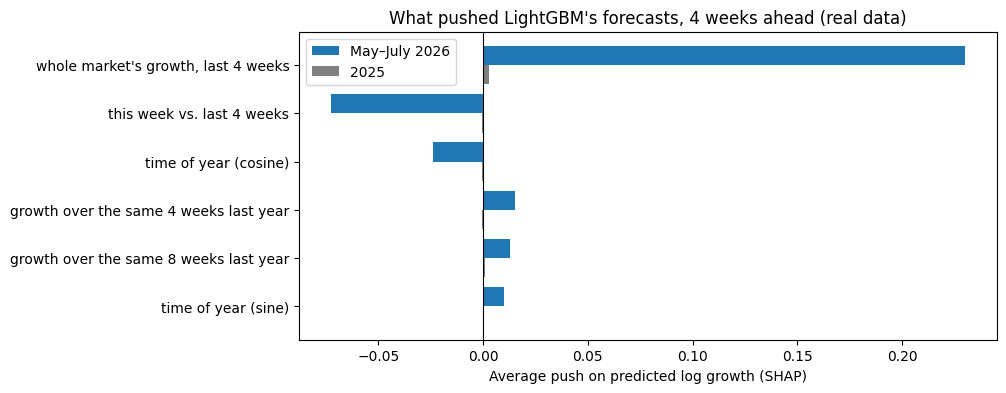

In [6]:
inputs = [c for c in shap.columns if c.startswith("shap_")]
window = shap["date"].between("2026-05-01", "2026-07-31")
year_2025 = shap["date"].dt.year == 2025
signed = pd.DataFrame({"May–Jul 2026": shap.loc[window, inputs].mean(),
                       "2025": shap.loc[year_2025, inputs].mean()})
signed.index = signed.index.str.replace("shap_", "")
top = signed.reindex(signed["May–Jul 2026"].abs().sort_values(ascending=False).index).head(6)
print(top.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(top))[::-1]
ax.barh(y + 0.2, top["May–Jul 2026"], height=0.4, label="May–July 2026")
ax.barh(y - 0.2, top["2025"], height=0.4, color="grey", label="2025")
ax.set_yticks(y)
ax.set_yticklabels([NAMES.get(f, f) for f in top.index])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Average push on predicted log growth (SHAP)")
ax.set_title(f"What pushed LightGBM's forecasts, 4 weeks ahead ({DATA_LABEL})")
ax.legend()
fig.savefig(FIGURES / "05_shap_post_spike.png", dpi=200, bbox_inches="tight")
plt.show()

### Was the market's fall outside the training data?

The whole market's 4-week growth, as a ratio (1.0 = no change). The dashed line is the lowest value in the training years (2017–2024).

Lowest market growth in training: 0.78 (week of 2020-03-29)
Lowest in May–July 2026:          0.62 (week of 2026-06-28)


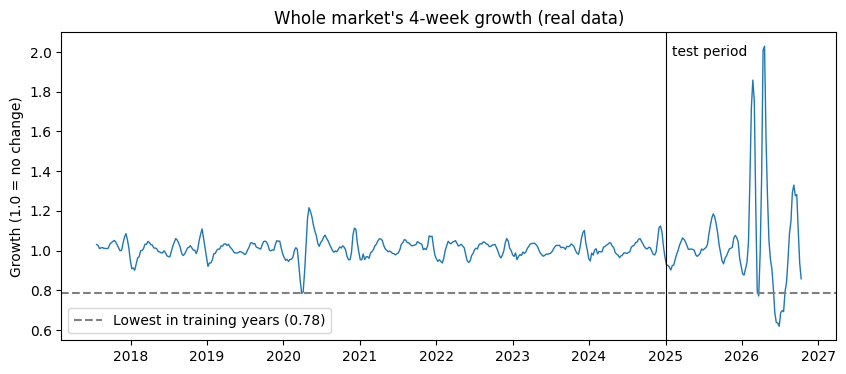

In [7]:
market = shap.drop_duplicates("date").set_index("date")["market_growth4"]
from rebuild_lightgbm import build_table
table, _ = build_table()
history = table.drop_duplicates("date").set_index("date")["market_growth4"].dropna()
train = history[history.index < "2025-01-01"]
lowest = np.exp(train.min())
print(f"Lowest market growth in training: {lowest:.2f} (week of {train.idxmin().date()})")
print(f"Lowest in May–July 2026:          {np.exp(market['2026-05-01':'2026-07-31'].min()):.2f} "
      f"(week of {market['2026-05-01':'2026-07-31'].idxmin().date()})")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.index, np.exp(history), linewidth=1)
ax.axhline(lowest, linestyle="--", color="grey", label=f"Lowest in training years ({lowest:.2f})")
ax.axvline(pd.Timestamp("2025-01-01"), color="black", linewidth=0.8)
ax.text(pd.Timestamp("2025-02-01"), ax.get_ylim()[1] * 0.97, "test period", va="top")
ax.set_title(f"Whole market's 4-week growth ({DATA_LABEL})")
ax.set_ylabel("Growth (1.0 = no change)")
ax.legend(loc="lower left")
fig.savefig(FIGURES / "05_market_growth_vs_training.png", dpi=200, bbox_inches="tight")
plt.show()

## What this shows

Real data, 137 styles, LightGBM test period January 2025 – September 2026.

1. **Overall drivers (4 weeks ahead):** this week vs. the last 4 weeks (mean |SHAP| 0.064), growth over
   the same weeks last year (0.035 for 4 weeks, 0.019 for 8 weeks) and the whole market's growth (0.026).
   At 8 weeks ahead, last year's growth dominates (0.097): the longer the horizon, the more the model
   relies on the yearly cycle.
2. **No memorising of styles:** the style itself is not an input, and its category ranks 14th of 21
   (0.003). The style's own recent growth ranks last (0.001), so the model does not simply chase trends.
3. **The simpler models agree:** logistic regression gives its largest weights to the same inputs
   (this week vs. last 4 weeks +0.86, last year's growth +0.69 and +0.55) and a negative weight to market
   growth (−0.28): after the market falls, a rise becomes more likely. Lasso shows the same pattern
   (market growth −0.056, style growth relative to the market −0.112).
4. **Why the post-spike rebound forecasts:** the rebuilt model reproduces the saved forecasts exactly.
   In May–July 2026, market growth pushed forecasts up by +0.23 on average (log growth, about +26%),
   compared with +0.003 in 2025; this week vs. the last 4 weeks pulled them down by −0.07. The market
   fell to 0.62 of its level 4 weeks earlier (week of 28 June 2026), far below the lowest value in the
   training years (0.78, week of 29 March 2020), which was followed by a quick rebound. Tree models cannot
   extrapolate beyond the training range, so the model treated June 2026 like the most extreme drop it
   had seen and expected the same recovery.